# 05 · Sleeve 2: factor-ranked long/short

Within each segment with at least four investable names: long the top ranks and short the bottom on a composite of value, balance-sheet strength and freight-beta momentum. Dollar-neutral per segment, inverse-volatility legs, weekly rebalance.

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

In [2]:
from shiplab import metrics
grid = pd.read_parquet(R / "grid_returns.parquet")
picks = pd.read_csv(R / "walk_forward_picks.csv", index_col=0)
cols = [c for c in grid.columns if c.startswith("factor")]
tab = pd.DataFrame({c: metrics.summary(grid[c].loc["2011":"2022"]) for c in cols}).T
display(tab[["ann_return", "ann_vol", "sharpe", "max_drawdown"]].round(3))
display(picks[["factor"]].rename(columns={"factor": "chosen for the year (prior data only)"}))

,ann_return,ann_vol,sharpe,max_drawdown
"factor|q=0.33|w=(1, 0, 0)",0.021,0.045,0.491,-0.084
"factor|q=0.33|w=(1, 1, 1)",0.015,0.040,0.404,-0.102
"factor|q=0.33|w=(1, 0, 1)",0.033,0.042,0.791,-0.072
"factor|q=0.50|w=(1, 0, 0)",0.014,0.048,0.311,-0.095
"factor|q=0.50|w=(1, 1, 1)",0.006,0.046,0.159,-0.165
"factor|q=0.50|w=(1, 0, 1)",0.030,0.046,0.676,-0.078


,chosen for the year (prior data only)
2014,NaN
2015,"factor|q=0.50|w=(1, 0, 1)"
2016,"factor|q=0.33|w=(1, 0, 1)"
2017,"factor|q=0.33|w=(1, 0, 1)"
2018,"factor|q=0.33|w=(1, 0, 0)"
2019,"factor|q=0.33|w=(1, 0, 0)"
2020,"factor|q=0.33|w=(1, 0, 0)"
2021,"factor|q=0.33|w=(1, 0, 1)"
2022,"factor|q=0.33|w=(1, 0, 1)"


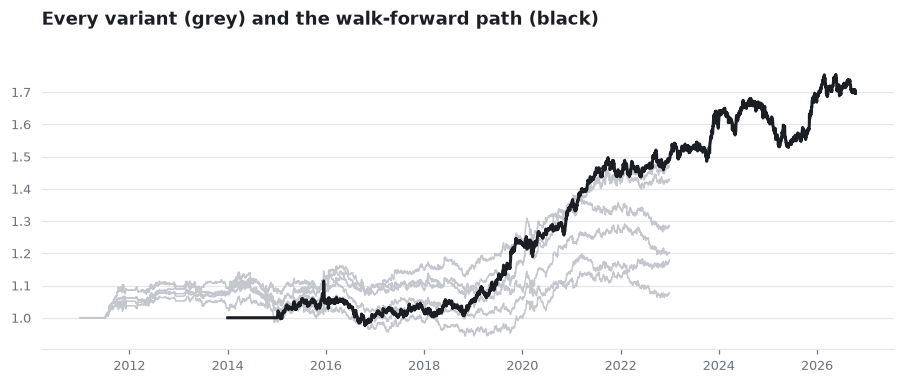

In [3]:
from shiplab import style
style.apply()
fig, ax = plt.subplots(figsize=(10, 3.4))
for c in cols:
    ax.plot((1 + grid[c].loc["2011":"2022"]).cumprod(), color="#C4C8CE", lw=1)
if "sleeve_factor" in strat:
    s = strat["sleeve_factor"].dropna()
    ax.plot((1 + s).cumprod(), color=style.INK, lw=2)
ax.set_title("Every variant (grey) and the walk-forward path (black)")
plt.show()